# UCI CKD: how much of the 99% comes from the diagnosis itself?

Most published CKD models are trained on the UCI Chronic Kidney Disease dataset (400 patients) and report accuracy close to 100%. This notebook reproduces that result and then removes features tier by tier, following Section 3 and Section 6 of `documentation/preregistration.md`:

1. **All features**
2. **Without Tier 1** (the features that define the diagnosis: creatinine, urea, albumin, specific gravity, red cells in urine)
3. **Without Tier 1 and Tier 2** (also removes consequences of established CKD, such as anemia and potassium)
4. **Tier 3 only** (what is known before any lab test: age, blood pressure, hypertension, diabetes, coronary artery disease)

Each step uses exactly the same procedure as the NHANES models: an 80/20 stratified split, the same three algorithms, the same preprocessing pipeline, 5-fold cross-validation, F2 as the primary metric, and a decision threshold tuned inside the training folds. The pre-registered expectations being tested are:

- **H1:** with all features, accuracy will be above 95%.
- **H2:** performance will drop clearly once Tier 1 and Tier 2 are removed.

## 1. Setup

The cleaning and tier lists are in `src/uci.py`. The preprocessing, tuning and scoring code is in `src/modeling.py`, which is the same file the NHANES notebook uses, so both datasets go through identical steps.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

import modeling
import plot_style
import uci

plot_style.apply()
FIGURE_DIR = PROJECT_ROOT / "documentation" / "figures"

raw = pd.read_csv(PROJECT_ROOT / "data" / "original" / "uci" / "chronic_kidney_disease.csv")
print(raw.shape)
raw.head()

(400, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,ckd


## 2. Data quality

### 2.1 Stray characters and impossible values

The raw file has a few text entries with tab characters, so `"ckd\t"` would count as a third class and `"\tno"` as a third answer for diabetes. Some lab values are also outside anything a living patient could have.

**What to look at:** the counts before cleaning, and that they are all gone after `uci.clean`.

In [2]:
text_columns = uci.CATEGORICAL + ["class"]
has_tab = raw[text_columns].apply(lambda column: column.str.contains("\t", na=False))
print("Entries with a tab, by column:")
print(has_tab.sum()[has_tab.sum() > 0])

print("\nImpossible values:")
for column, (low, high) in uci.IMPOSSIBLE.items():
    bad = raw[(raw[column] < low) | (raw[column] > high)][column]
    print(f"  {column}: {bad.tolist()}  (allowed {low} to {high})")

df = uci.clean(raw)
print("\nAfter cleaning, class values:", df["ckd"].value_counts().to_dict())
print("Diabetes answers:", df["dm"].value_counts(dropna=False).to_dict())
print("Duplicate rows:", df.duplicated().sum())

Entries with a tab, by column:
dm       1
class    2
dtype: int64

Impossible values:
  sod: [4.5]  (allowed 100 to 200)
  pot: [39.0, 47.0]  (allowed 1.5 to 15)

After cleaning, class values: {1: 250, 0: 150}
Diabetes answers: {'no': 261, 'yes': 137, nan: 2}
Duplicate rows: 0


**Finding:** Three text entries had a stray tab: two labels written as `"ckd\t"` and one diabetes answer written as `"\tno"`. Without cleaning, the label would have three classes and diabetes three answers. Three lab values are impossible for a living patient: one sodium of 4.5 mEq/L (normal is about 135 to 145) and two potassium values of 39 and 47 mEq/L (normal is about 3.5 to 5). These look like typing errors, for example 4.5 entered in the sodium column instead of the potassium column. There are no duplicate rows.

**Action:** `uci.clean` strips the tabs and sets the three impossible values to missing, so they are filled in inside the pipeline like any other missing value. After cleaning there are 250 CKD and 150 non-CKD patients, and diabetes only has yes and no.

### 2.2 Missing values by tier

**What to look at:** which tiers have the most missing values. Missing lab results usually mean the test was not ordered.

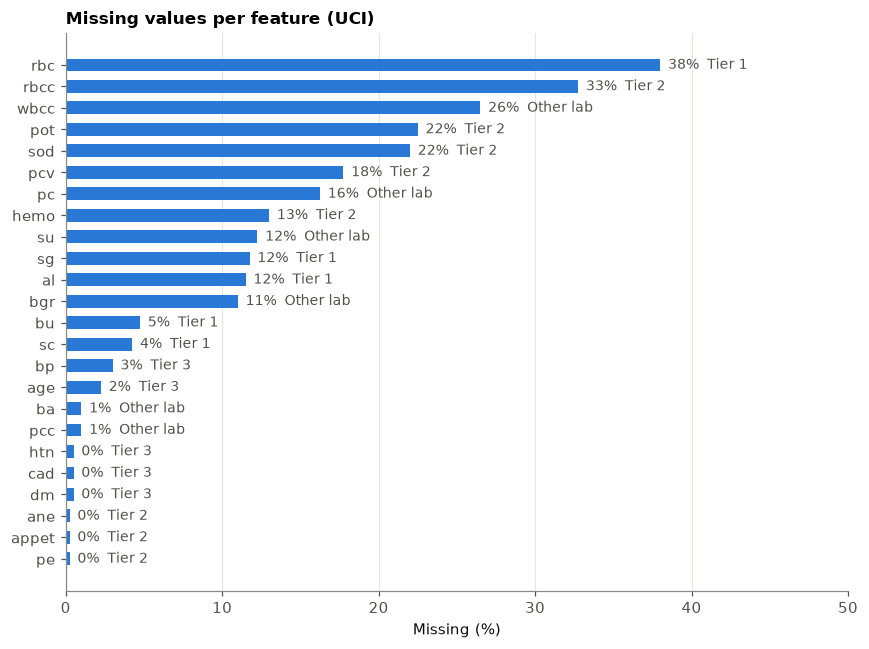

In [3]:
tier_of = {feature: tier for tier, features in uci.TIERS.items() for feature in features}
tier_names = {"tier1": "Tier 1", "tier2": "Tier 2", "other_lab": "Other lab", "tier3": "Tier 3"}

missing = (df[uci.ALL_FEATURES].isna().mean() * 100).to_frame("percent missing")
missing["tier"] = missing.index.map(lambda f: tier_names[tier_of[f]])
missing = missing.sort_values("percent missing")

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(missing.index, missing["percent missing"], color=plot_style.NO_CKD, height=0.6)
for y, (value, tier) in enumerate(zip(missing["percent missing"], missing["tier"])):
    ax.text(value + 0.5, y, f"{value:.0f}%  {tier}", va="center", fontsize=9, color=plot_style.TEXT_SECONDARY)
ax.set(title="Missing values per feature (UCI)", xlabel="Missing (%)", xlim=(0, 50))
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "uci_01_missing.png")
plt.show()

**Finding:** Missing values are much more common in the lab features than in Tier 3. Red blood cells in urine (`rbc`, Tier 1) is missing for 38% of patients and red blood cell count (`rbcc`, Tier 2) for 33%. All five Tier 3 features are 3% missing or less. This fits how hospital records work: a lab value is only there if the test was ordered.

**Action:** keep every feature, as pre-registered, and fill in missing values inside the pipeline (median for numbers, most common answer for text), exactly like NHANES. No feature is dropped, because removing features is what the ablation itself does in a controlled way.

### 2.3 Class balance and other notes

**What to look at:** the share of CKD, compared with the 16.5% found in the NHANES population.

In [4]:
print(df["ckd"].value_counts().rename({1: "ckd", 0: "not ckd"}))
print(f"CKD share: {df['ckd'].mean():.1%}")
print(f"F2 of 'refer everyone' at this prevalence: {5 * df['ckd'].mean() / (4 * df['ckd'].mean() + 1):.3f}")
print(f"\nAge range: {df['age'].min():.0f} to {df['age'].max():.0f}, people under 20: {(df['age'] < 20).sum()}")
print("Blood pressure values:", sorted(df["bp"].dropna().unique()))

ckd
ckd        250
not ckd    150
Name: count, dtype: int64
CKD share: 62.5%
F2 of 'refer everyone' at this prevalence: 0.893

Age range: 2 to 90, people under 20: 21
Blood pressure values: [np.float64(50.0), np.float64(60.0), np.float64(70.0), np.float64(80.0), np.float64(90.0), np.float64(100.0), np.float64(110.0), np.float64(120.0), np.float64(140.0), np.float64(180.0)]


**Finding:** 62.5% of the UCI patients have CKD, almost four times the 16.5% in the NHANES population. This is a hospital sample, not a screening population. At this prevalence, simply referring everyone already gives F2 = 0.893, and always saying "CKD" gives 62.5% accuracy, so high scores on UCI are much easier to reach than in real screening. The dataset also includes 21 patients under 20 (the youngest is 2), while the NHANES model is only for adults. Blood pressure is only recorded in steps of 10 mmHg, and since most values are 60 to 90, it is most likely diastolic pressure.

**Action:** report ROC-AUC alongside F2 in the ablation, because ROC-AUC does not depend on prevalence. Children are kept because the goal here is to reproduce the published setup, not to build a model for use.

## 3. Train/test split

Same rule as NHANES: 80/20, stratified on the label, `random_state = 42`. The test rows are not used until section 6.

In [5]:
train, test = train_test_split(df, test_size=0.2, stratify=df["ckd"], random_state=modeling.RANDOM_STATE)
print(f"train: {len(train)} rows, {train['ckd'].mean():.1%} CKD")
print(f"test:  {len(test)} rows, {test['ckd'].mean():.1%} CKD")

train: 320 rows, 62.5% CKD
test:  80 rows, 62.5% CKD


## 4. How much does each single feature know?

Before training any model, I measure how well each feature separates the classes **on its own**, using ROC-AUC on the training rows. An AUC of 0.5 is a coin flip and 1.0 is perfect separation. Text answers are turned into 1 for the abnormal answer (abnormal, present, yes, poor) and 0 otherwise. For features where a lower value means CKD (such as hemoglobin), the AUC is flipped so that 0.5 is always the floor.

**What to look at:** where the Tier 1 and Tier 2 features sit compared with Tier 3.

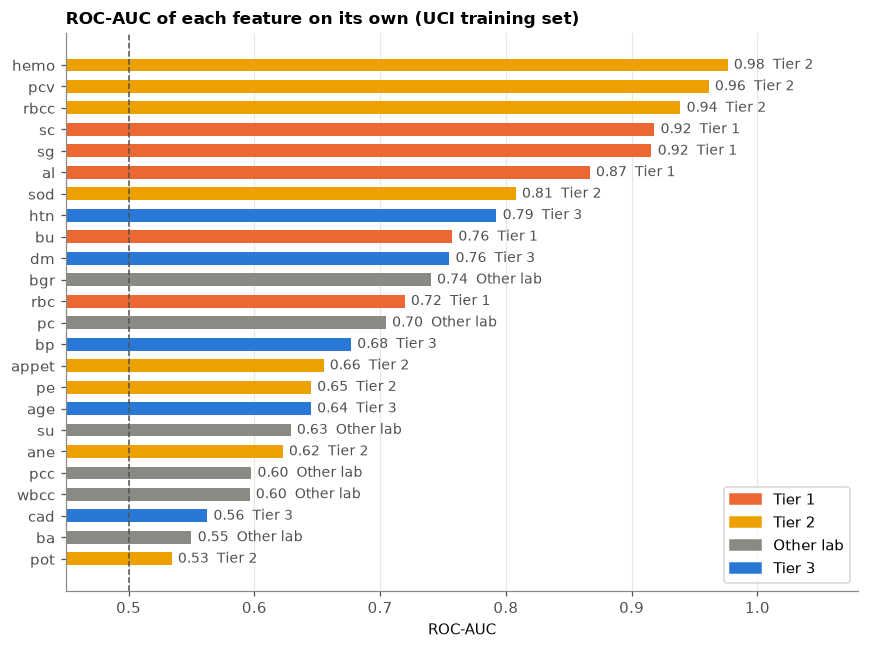

,feature,tier,auc
5,hemo,Tier 2,0.976
6,pcv,Tier 2,0.961
7,rbcc,Tier 2,0.939
0,sc,Tier 1,0.918
3,sg,Tier 1,0.916
2,al,Tier 1,0.867
10,sod,Tier 2,0.808
21,htn,Tier 3,0.792
1,bu,Tier 1,0.757
22,dm,Tier 3,0.755


In [6]:
abnormal = {"abnormal": 1, "normal": 0, "present": 1, "notpresent": 0, "yes": 1, "no": 0, "poor": 1, "good": 0}

rows = []
for feature in uci.ALL_FEATURES:
    values = train[feature].map(abnormal) if feature in uci.CATEGORICAL else train[feature]
    known = values.notna()
    auc = roc_auc_score(train.loc[known, "ckd"], values[known])
    rows.append({"feature": feature, "tier": tier_names[tier_of[feature]], "auc": max(auc, 1 - auc)})
single = pd.DataFrame(rows).sort_values("auc")

tier_colors = {"Tier 1": plot_style.CKD, "Tier 2": "#eda100", "Other lab": plot_style.AXIS, "Tier 3": plot_style.NO_CKD}
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(single["feature"], single["auc"], color=single["tier"].map(tier_colors), height=0.6)
for y, row in enumerate(single.itertuples()):
    ax.text(row.auc + 0.005, y, f"{row.auc:.2f}  {row.tier}", va="center", fontsize=9, color=plot_style.TEXT_SECONDARY)
ax.axvline(0.5, color=plot_style.TEXT_SECONDARY, linestyle="--", linewidth=1)
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in tier_colors.values()]
ax.legend(handles, tier_colors.keys(), loc="lower right", frameon=True)
ax.set(title="ROC-AUC of each feature on its own (UCI training set)", xlabel="ROC-AUC", xlim=(0.45, 1.08))
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "uci_02_single_feature_auc.png")
plt.show()

single.sort_values("auc", ascending=False).round(3)

**Finding:** Several single features almost separate the classes on their own. Hemoglobin alone has ROC-AUC 0.98, packed cell volume 0.96, red cell count 0.94, and serum creatinine and specific gravity 0.92 each. The strongest features are Tier 2 (the anemia that follows CKD) and Tier 1 (the measurements that define it). The best Tier 3 feature is hypertension at 0.79.

This explains the near-perfect accuracy in the literature: a model does not need to learn much when one blood test already sorts the patients. It also shows that removing only Tier 1 will not be enough, because the Tier 2 features carry almost the same information.

**Action:** none. This is the expectation the ablation in section 5 tests.

## 5. The ablation: three models on four feature sets

For every feature set and every model, `modeling.tune` runs a grid search scored by F2 on the 5 shared folds, with the decision threshold tuned inside each training fold. `modeling.cross_validate_model` then refits the best settings on each fold and records all the metrics. This cell takes a few minutes.

Because UCI is 62.5% CKD, even "refer everyone" gets F2 = 0.89 here (section 2.3). F2 is still the primary metric so the procedure matches NHANES, but **ROC-AUC is the clearest measure of what each feature set actually knows**, because it does not depend on the prevalence or the threshold.

In [7]:
y_train = train["ckd"]
results = {}       # (feature set, model) -> fold scores
selected = {}      # feature set -> (model name, reason, fitted search)

for set_name, features in uci.FEATURE_SETS.items():
    numeric, categorical = uci.column_types(features)
    fold_scores, searches = {}, {}
    for model_name, (model, grid) in modeling.make_models().items():
        preprocessor = modeling.make_preprocessor(numeric, [], categorical)
        search = modeling.tune(preprocessor, model, grid, train[features], y_train)
        scores, _, _ = modeling.cross_validate_model(search.best_estimator_, train[features], y_train)
        fold_scores[model_name] = scores
        searches[model_name] = search
        results[(set_name, model_name)] = scores
    name, reason = modeling.select_model(fold_scores)
    selected[set_name] = (name, reason, searches[name])
    print(f"{set_name}: {reason}")

All features: Logistic Regression had the highest mean F2 (0.997) and is also simpler than Random Forest (0.995), so it is selected.


Without Tier 1: Logistic Regression had the highest mean F2 (0.984) and is also simpler than Gradient Boosting (0.981), so it is selected.


Without Tier 1 and 2: Gradient Boosting had the highest mean F2 (0.953), but Random Forest (0.950) is within one SD (0.030), so the simpler model, Random Forest, is selected.


Tier 3 only: Gradient Boosting had the highest mean F2 (0.902), but Logistic Regression (0.898) is within one SD (0.040), so the simpler model, Logistic Regression, is selected.


In [8]:
rows = []
for (set_name, model_name), scores in results.items():
    rows.append({"feature set": set_name, "model": model_name,
                 "F2": f"{scores['f2'].mean():.3f} +/- {scores['f2'].std():.3f}",
                 "ROC-AUC": f"{scores['roc_auc'].mean():.3f} +/- {scores['roc_auc'].std():.3f}",
                 "accuracy": f"{scores['accuracy'].mean():.3f} +/- {scores['accuracy'].std():.3f}",
                 "recall": f"{scores['recall'].mean():.3f}",
                 "specificity": f"{scores['specificity'].mean():.3f}"})
cv_table = pd.DataFrame(rows)
cv_table.to_csv(PROJECT_ROOT / "models" / "uci_ablation_cv.csv", index=False)
cv_table

,feature set,model,F2,ROC-AUC,accuracy,recall,specificity
0,All features,Logistic Regression,0.997 +/- 0.007,1.000 +/- 0.000,0.991 +/- 0.021,1.000,0.975
1,All features,Random Forest,0.995 +/- 0.005,0.999 +/- 0.001,0.984 +/- 0.016,1.000,0.958
2,All features,Gradient Boosting,0.995 +/- 0.009,1.000 +/- 0.001,0.994 +/- 0.009,0.995,0.992
3,Without Tier 1,Logistic Regression,0.984 +/- 0.013,0.995 +/- 0.006,0.969 +/- 0.031,0.990,0.933
4,Without Tier 1,Random Forest,0.979 +/- 0.007,0.994 +/- 0.006,0.972 +/- 0.013,0.980,0.958
5,Without Tier 1,Gradient Boosting,0.981 +/- 0.010,0.992 +/- 0.006,0.969 +/- 0.016,0.985,0.942
6,Without Tier 1 and 2,Logistic Regression,0.907 +/- 0.019,0.929 +/- 0.031,0.744 +/- 0.041,0.970,0.367
7,Without Tier 1 and 2,Random Forest,0.950 +/- 0.028,0.980 +/- 0.018,0.906 +/- 0.062,0.965,0.808
8,Without Tier 1 and 2,Gradient Boosting,0.953 +/- 0.030,0.975 +/- 0.021,0.938 +/- 0.029,0.955,0.908
9,Tier 3 only,Logistic Regression,0.898 +/- 0.018,0.897 +/- 0.036,0.691 +/- 0.051,0.980,0.208


The figure shows the cross-validation mean for each model, with a bar for one standard deviation across the 5 folds. These are **validation results only**. The test set has not been touched yet.

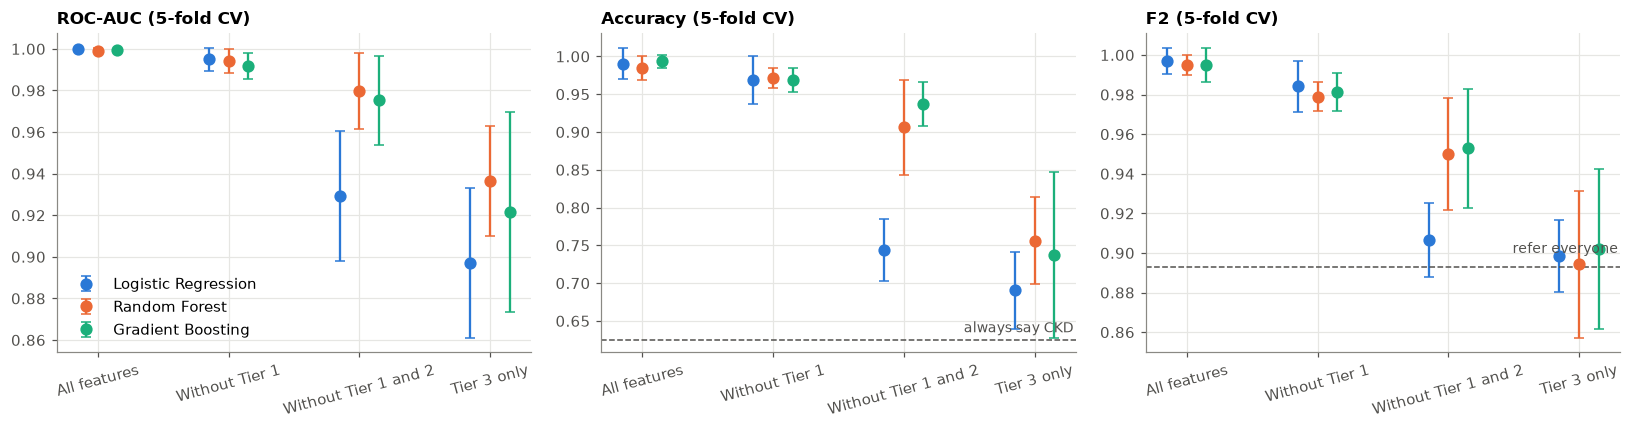

In [9]:
model_colors = {"Logistic Regression": plot_style.NO_CKD, "Random Forest": plot_style.CKD, "Gradient Boosting": "#1baf7a"}
set_names = list(uci.FEATURE_SETS)
x = np.arange(len(set_names))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, metric, title in zip(axes, ["roc_auc", "accuracy", "f2"], ["ROC-AUC", "Accuracy", "F2"]):
    for offset, (model_name, color) in zip([-0.15, 0, 0.15], model_colors.items()):
        means = [results[(s, model_name)][metric].mean() for s in set_names]
        sds = [results[(s, model_name)][metric].std() for s in set_names]
        ax.errorbar(x + offset, means, yerr=sds, fmt="o", color=color, markersize=7, capsize=3, label=model_name)
    ax.set_xticks(x, set_names, rotation=15)
    ax.set(title=f"{title} (5-fold CV)")
axes[1].axhline(df["ckd"].mean(), color=plot_style.TEXT_SECONDARY, linestyle="--", linewidth=1)
axes[1].text(3.3, df["ckd"].mean() + 0.01, "always say CKD", ha="right", fontsize=9, color=plot_style.TEXT_SECONDARY)
axes[2].axhline(5 * df["ckd"].mean() / (4 * df["ckd"].mean() + 1), color=plot_style.TEXT_SECONDARY, linestyle="--", linewidth=1)
axes[2].text(3.3, 0.9, "refer everyone", ha="right", fontsize=9, color=plot_style.TEXT_SECONDARY)
axes[0].legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "uci_03_ablation_cv.png")
plt.show()

**Finding:**

- **All features:** every model reaches about 99% accuracy and ROC-AUC 1.00 in cross-validation. This reproduces the published results, so **H1 holds**.
- **Without Tier 1:** almost nothing changes (ROC-AUC 0.99, accuracy about 97%). The Tier 2 anemia features fill the gap, as section 4 predicted.
- **Without Tier 1 and Tier 2:** accuracy falls to 0.74 to 0.94 and ROC-AUC to 0.93 to 0.98. The "other lab" features (blood glucose, urine sugar, pus cells) still carry a lot.
- **Tier 3 only:** accuracy falls to 0.69 to 0.76 (always saying CKD gets 0.625) and specificity collapses to 0.21 to 0.44. Most non-CKD patients would be referred. F2 is 0.89 to 0.90, the same as referring everyone (0.893).

So **H2 holds**: performance drops clearly once Tier 1 and Tier 2 are gone, and with only the information available before a lab test, no model beats "refer everyone" on the primary metric. The ROC-AUC of 0.90 to 0.94 with Tier 3 only is still much higher than I expect on NHANES. UCI compares hospital CKD patients, many with clearly abnormal blood results, against people without CKD, so even simple risk factors like hypertension separate them much more easily than in a general population.

**Action:** none for the method. The model selection results in the cell above follow the pre-registered rule, including two cases where the tie-break picked the simpler model.

## 6. Test set: each selected model, scored once

For each feature set, the model chosen by the pre-registered rule in section 5 is refit on all training rows (`GridSearchCV` already did this) and scored **once** on the 80 test rows. This is the only place the UCI test rows are used.

In [10]:
rows = []
for set_name, (model_name, _, search) in selected.items():
    features = uci.FEATURE_SETS[set_name]
    model = search.best_estimator_
    proba = model.predict_proba(test[features])[:, 1]
    pred = model.predict(test[features])
    scores = modeling.score_predictions(test["ckd"], pred, proba)
    rows.append({"feature set": set_name, "selected model": model_name, **{k: round(v, 3) for k, v in scores.items()}})
test_table = pd.DataFrame(rows).drop(columns=["brier"])
test_table.to_csv(PROJECT_ROOT / "models" / "uci_ablation_test.csv", index=False)
test_table

,feature set,selected model,f2,recall,precision,specificity,f1,accuracy,roc_auc,pr_auc
0,All features,Logistic Regression,0.984,0.98,1.000,1.000,0.990,0.988,1.000,1.000
1,Without Tier 1,Logistic Regression,0.948,0.94,0.979,0.967,0.959,0.950,0.969,0.986
2,Without Tier 1 and 2,Random Forest,0.980,1.00,0.909,0.833,0.952,0.938,0.995,0.997
3,Tier 3 only,Logistic Regression,0.897,0.98,0.671,0.200,0.797,0.688,0.899,0.955


**Finding:** The test results match the cross-validation pattern. With all features, the selected model gets 98.8% accuracy and ROC-AUC 1.00. With Tier 3 only, accuracy is 68.8% and specificity 0.20: it catches 98% of CKD patients but refers 80% of the non-CKD patients too. The test set has only 80 patients (30 without CKD), so a single misclassified patient changes specificity by more than 3 points, and these numbers should be read together with the cross-validation results, not alone.

The "without Tier 1 and 2" test result (F2 0.980) is higher than its cross-validation mean (0.950). With 80 test patients this is within normal variation.

**Action:** none. The UCI test rows are not used again.

## 7. Summary

| Feature set | CV ROC-AUC (best model) | CV accuracy range | What it shows |
|---|---|---|---|
| All features | 1.00 | 0.98 to 0.99 | Reproduces the ~99% in the literature (H1 holds) |
| Without Tier 1 | 0.99 | 0.97 | Tier 2 anemia features carry almost the same information |
| Without Tier 1 and 2 | 0.98 | 0.74 to 0.94 | Other lab values still help a lot |
| Tier 3 only | 0.94 | 0.69 to 0.76 | F2 no better than referring everyone (H2 holds) |

The near-perfect UCI results come from features that either define CKD or follow from it, measured in a hospital sample where 62.5% of patients have CKD. Neither is available at a first screening. This is why the main model in this project is trained on NHANES, a general population sample, using only Tier 3 features.